# Performing a reconstruction

In this example, a full reconstruction procedure is performed via the [MPR](#spring.MPR) object.

As a first step, we load the experimental data 

In [1]:
import numpy as np
data = np.load('data/example_A_1.npz')


Once the data is loaded, we define the `spring.Pattern` object. The pattern is cropped to a size `1024x1024` pixel centered on the `center` position, and then rescaled to a size of `256x256`. Values above `3.4e4` are considered to be saturated.

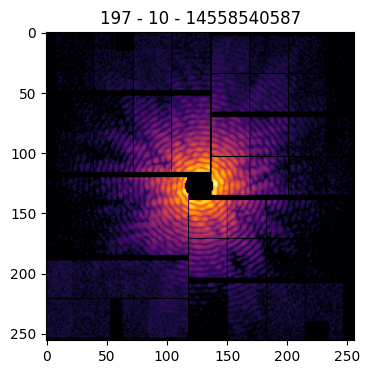

In [3]:
from spring import Pattern
patt = Pattern(pattern=data['pattern'], 
               mask=data['mask'], 
               center=data['center'], 
               pid=data['pid'],
               cropsize=1024,
               size=256,
               satvalue=3e4)
patt.plot()

The second step involves the loading of the difinition of the settings. Here we initialize the `spring.Settings` object with the default values, and set the number of iterations of IA and the starting dimension of the support function. The number of GPUs to use is set to 1.

In [7]:
from spring import Settings
sett = Settings().set('IA','it', 50).set('init','supportsize',70).set('global','gpus',1)

It is now possible to run the reconstruction by using the `spring.MPR.run()` method.

In [8]:
from spring import MPR

rec = MPR(pattern=patt, settings=sett).run()

Selected GPUs:
  - NVIDIA GeForce RTX 3090 (Id: 0, load: 0%)
Initializing solver... Done.
Initializing algorithms... Done.
Initializing population... Done.
... Running main loop ...
Generation 0/100
	OS: 13.37  Repl: 0.000
	Best	 Err. 5.379e-02 ; Compl. 7.705e-03 ; Sym. 7.221e-01 ; Sum. 7.349e+02 ;
	Mean	 Err. 6.267e-02 ; Compl. 1.462e-02 ; Sym. 4.887e-01 ; Sum. 7.859e+02 ;
	Avg 	 Err. 6.348e-01 ; Compl. 7.629e-04 ; Sym. 8.541e-01 ; Sum. 7.524e+02 ;

Generation 1/100
	OS: 9.08  Repl: 0.508
	Best	 Err. 4.764e-02 ; Compl. 1.035e-02 ; Sym. 6.695e-01 ; Sum. 5.768e+02 ;
	Mean	 Err. 5.670e-02 ; Compl. 2.218e-02 ; Sym. 5.288e-01 ; Sum. 6.925e+02 ;
	Avg 	 Err. 6.266e-01 ; Compl. 7.527e-04 ; Sym. 8.586e-01 ; Sum. 7.523e+02 ;

Generation 2/100
	OS: 10.82  Repl: 0.430
	Best	 Err. 4.806e-02 ; Compl. 1.015e-02 ; Sym. 7.567e-01 ; Sum. 6.631e+02 ;
	Mean	 Err. 5.980e-02 ; Compl. 2.385e-02 ; Sym. 5.777e-01 ; Sum. 6.528e+02 ;
	Avg 	 Err. 4.546e-01 ; Compl. 1.359e-03 ; Sym. 9.074e-01 ; Sum. 6.698e+02 ;



During the reconstruction some log information is shown, informing about the status of the reconstruction. The object returned by the `MPR.run()` method is a `spring.Reconstruction`, which contains the outcome of the phase retrieval procedure (see [here](Result) for more information). It provides several methods. Among them, the helper method `spring.Reconstruction.plot()` gives an overview of the outcome:

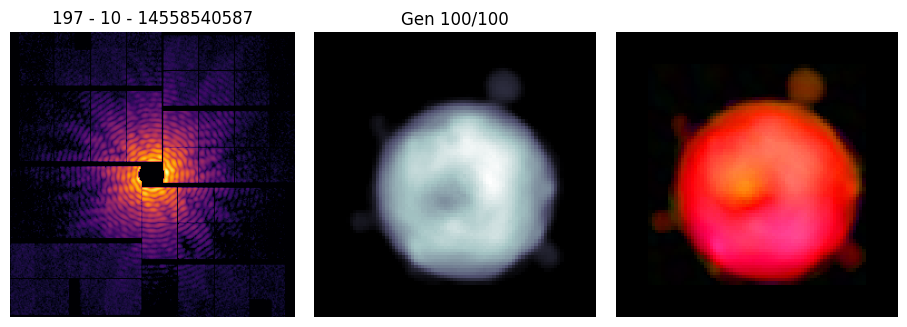

In [9]:
rec.plot()